## Código copiado e alterado apenas o necessário do projeto de algoritmos lineares com a mesma base

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    PrecisionRecallDisplay,
    recall_score,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# estudo árvores
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

from src.config import DADOS_LIMPOS
from src.models import RANDOM_STATE

sns.set_theme(palette="bright", style="white")

In [4]:
df = pd.read_parquet(DADOS_LIMPOS)

df.head()

,area_mean,area_se,area_worst,compactness_mean,compactness_se,compactness_worst,concave points_mean,concave points_se,concave points_worst,concavity_mean,...,radius_worst,smoothness_mean,smoothness_se,smoothness_worst,symmetry_mean,symmetry_se,symmetry_worst,texture_mean,texture_se,texture_worst
0,1001.0,153.40,2019.0,0.27760,0.04904,0.6656,0.14710,0.01587,0.2654,0.3001,...,25.38,0.11840,0.006399,0.1622,0.2419,0.03003,0.4601,10.38,0.9053,17.33
1,1326.0,74.08,1956.0,0.07864,0.01308,0.1866,0.07017,0.01340,0.1860,0.0869,...,24.99,0.08474,0.005225,0.1238,0.1812,0.01389,0.2750,17.77,0.7339,23.41
2,1203.0,94.03,1709.0,0.15990,0.04006,0.4245,0.12790,0.02058,0.2430,0.1974,...,23.57,0.10960,0.006150,0.1444,0.2069,0.02250,0.3613,21.25,0.7869,25.53
3,386.1,27.23,567.7,0.28390,0.07458,0.8663,0.10520,0.01867,0.2575,0.2414,...,14.91,0.14250,0.009110,0.2098,0.2597,0.05963,0.6638,20.38,1.1560,26.50
4,1297.0,94.44,1575.0,0.13280,0.02461,0.2050,0.10430,0.01885,0.1625,0.1980,...,22.54,0.10030,0.011490,0.1374,0.1809,0.01756,0.2364,14.34,0.7813,16.67


In [5]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [6]:
y.head()

0    M
1    M
2    M
3    M
4    M
Name: diagnosis, dtype: object

In [7]:
le = LabelEncoder()

y = le.fit_transform(y)

y[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [8]:
le.classes_

array(['B', 'M'], dtype=object)

In [9]:
y[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0])

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

In [11]:
np.bincount(y_train) / len(y_train)

array([0.62676056, 0.37323944])

In [12]:
np.bincount(y_test) / len(y_test)

array([0.62937063, 0.37062937])

In [13]:
# mudar nosso classificador
clf = DecisionTreeClassifier()

clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [14]:
y_pred = clf.predict(X_test)

In [15]:
clf.score(X_test, y_test)

0.9440559440559441

O `score` do classificador retorna a acurácia do modelo, que é a proporção de predições corretas feitas pelo modelo. Podemos calcular a acurácia comparando as predições feitas pelo modelo com as respostas corretas. A acurácia é dada por:

$$
\text{acurácia} = \frac{\text{número de predições corretas}}{\text{número total de predições}} 
$$

Uma acurácia de 1.0 significa que o modelo fez todas as predições corretas, enquanto uma acurácia de 0.0 significa que o modelo fez todas as predições erradas.

In [16]:
accuracy_score(y_test, y_pred)

0.9440559440559441

### Matriz de confusão

A matriz de confusão é uma tabela que mostra o número de predições corretas e incorretas feitas pelo modelo. A matriz de confusão é dada por (considerando a ordem do Scikit-Learn):

$$
\begin{array}{|c|c|c|}
\hline
& \text{predição negativa} & \text{predição positiva} \\
\hline
\text{classe negativa} & TN & FP \\
\hline
\text{classe positiva} & FN & TP \\
\hline
\end{array}
$$


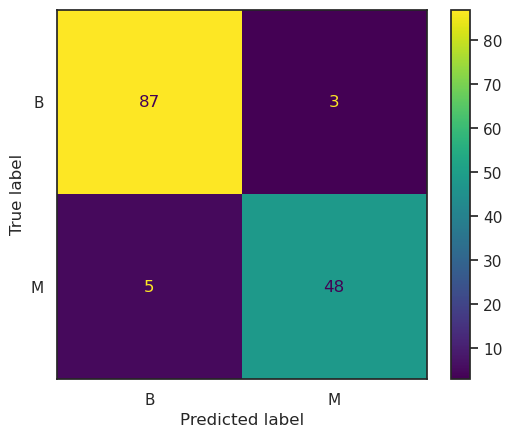

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_)

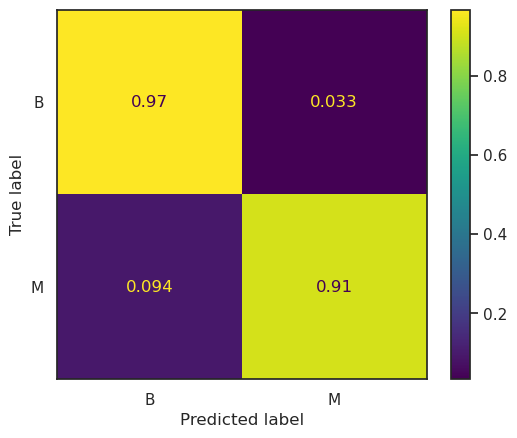

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, normalize="true")

### Recall

Uma outra métrica que podemos usar para avaliar a qualidade de um modelo de classificação é o recall. O recall é a proporção de exemplos da classe positiva que foram corretamente classificados pelo modelo. O recall é dado por:

$$
\text{recall} = \frac{TP}{P} = \frac{TP}{TP + FN}
$$

In [19]:
recall_score(y_test, y_pred)

0.9056603773584906

### Precision (Precisão)

A precisão é a proporção de exemplos classificados como positivos que são realmente positivos. A precisão é dada por:

$$
\text{precisão} = \frac{TP}{\text{pred }P} = \frac{TP}{TP + FP}
$$



In [20]:
precision_score(y_test, y_pred)

0.9411764705882353

### F Score

O F1 score é a média harmônica entre recall e precisão. A média harmônica é usada ao invés da média aritmética porque penaliza valores extremos. O F1 score é dado por:

$$
\text{F1 score} = 2 \times \frac{\text{precisão} \times \text{recall}}{\text{precisão} + \text{recall}}
$$

Por ser uma média harmônica, o F1 score é mais sensível a valores baixos de precisão ou recall. Por exemplo, se tivermos um modelo que tem precisão 1.0 e recall 0.0, o F1 score será 0.0. Se tivermos um modelo que tem precisão 0.0 e recall 1.0, o F1 score também será 0.0.




In [21]:
f1_score(y_test, y_pred)

0.9230769230769231

O F1 score é um caso especial da média $F_\beta$:

$$
F_\beta = (1 + \beta^2) \times \frac{\text{precisão} \times \text{recall}}{\beta^2 \times \text{precisão} + \text{recall}}
$$

Quando $\beta = 1$, temos o F1 score. Quando $\beta > 1$, o recall tem mais peso na média. Quando $\beta < 1$, a precisão tem mais peso na média.

In [22]:
fbeta_score(y_test, y_pred, beta=0.5)

0.933852140077821

In [23]:
fbeta_score(y_test, y_pred, beta=2)

0.9125475285171103

### Curva ROC

A curva ROC (Receiver Operating Characteristic) é uma curva que mostra a taxa de verdadeiros positivos (recall) em função da taxa de falsos positivos. A curva ROC é útil para avaliar a qualidade de um classificador binário em diferentes thresholds. A área sob a curva ROC (AUC) é uma métrica que varia entre 0.0 e 1.0, onde 0.0 significa um classificador ruim e 1.0 significa um classificador perfeito.



In [24]:
roc_auc = roc_auc_score(y_test, y_pred)
roc_auc

0.9361635220125786

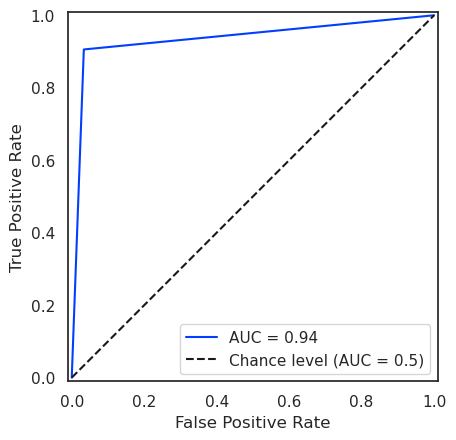

In [25]:
fpr, tpr, limiares = roc_curve(y_test, y_pred)

disp = RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc)
disp.plot(plot_chance_level=True)

### Curva Precision-Recall

A curva precision-recall é uma curva que mostra a precisão em função do recall. A curva precision-recall é útil para avaliar a qualidade de um classificador binário em diferentes thresholds. A área sob a curva precision-recall (AUC) é uma métrica que varia entre 0.0 e 1.0, onde 0.0 significa um classificador ruim e 1.0 significa um classificador perfeito.



In [26]:
average_precision = average_precision_score(y_test, y_pred)
average_precision

0.8873512724789084

In [27]:
y_test.mean()

0.3706293706293706

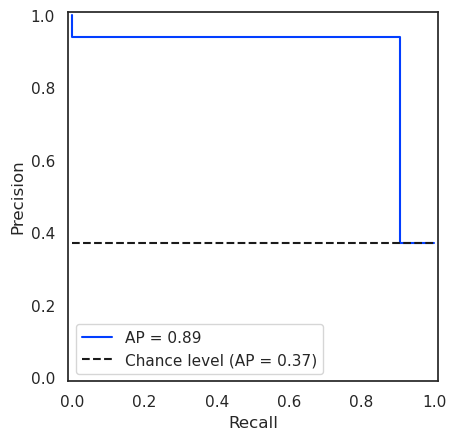

In [28]:
precision, recall, limiares = precision_recall_curve(y_test, y_pred)

disp = PrecisionRecallDisplay(
    precision=precision,
    recall=recall,
    average_precision=average_precision,
    prevalence_pos_label=y_test.mean()
)

disp.plot(plot_chance_level=True)

A reta de nível de chance no gráfico de Precision-Recall representa a precisão esperada de um classificador aleatório que faz previsões positivas independentemente das características dos dados.

É a linha que indica o desempenho de um modelo que adivinha aleatoriamente as classes dos exemplos, seguindo a mesma prevalência da classe positiva no conjunto de dados. Serve como uma linha de base para comparar o desempenho do seu modelo. Se o seu modelo não superar essa linha, ele não está melhor do que uma classificação aleatória.

### Classification Report

In [29]:
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

           B       0.95      0.97      0.96        90
           M       0.94      0.91      0.92        53

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143



## Visualizações e análises específicas para árvores de decisão

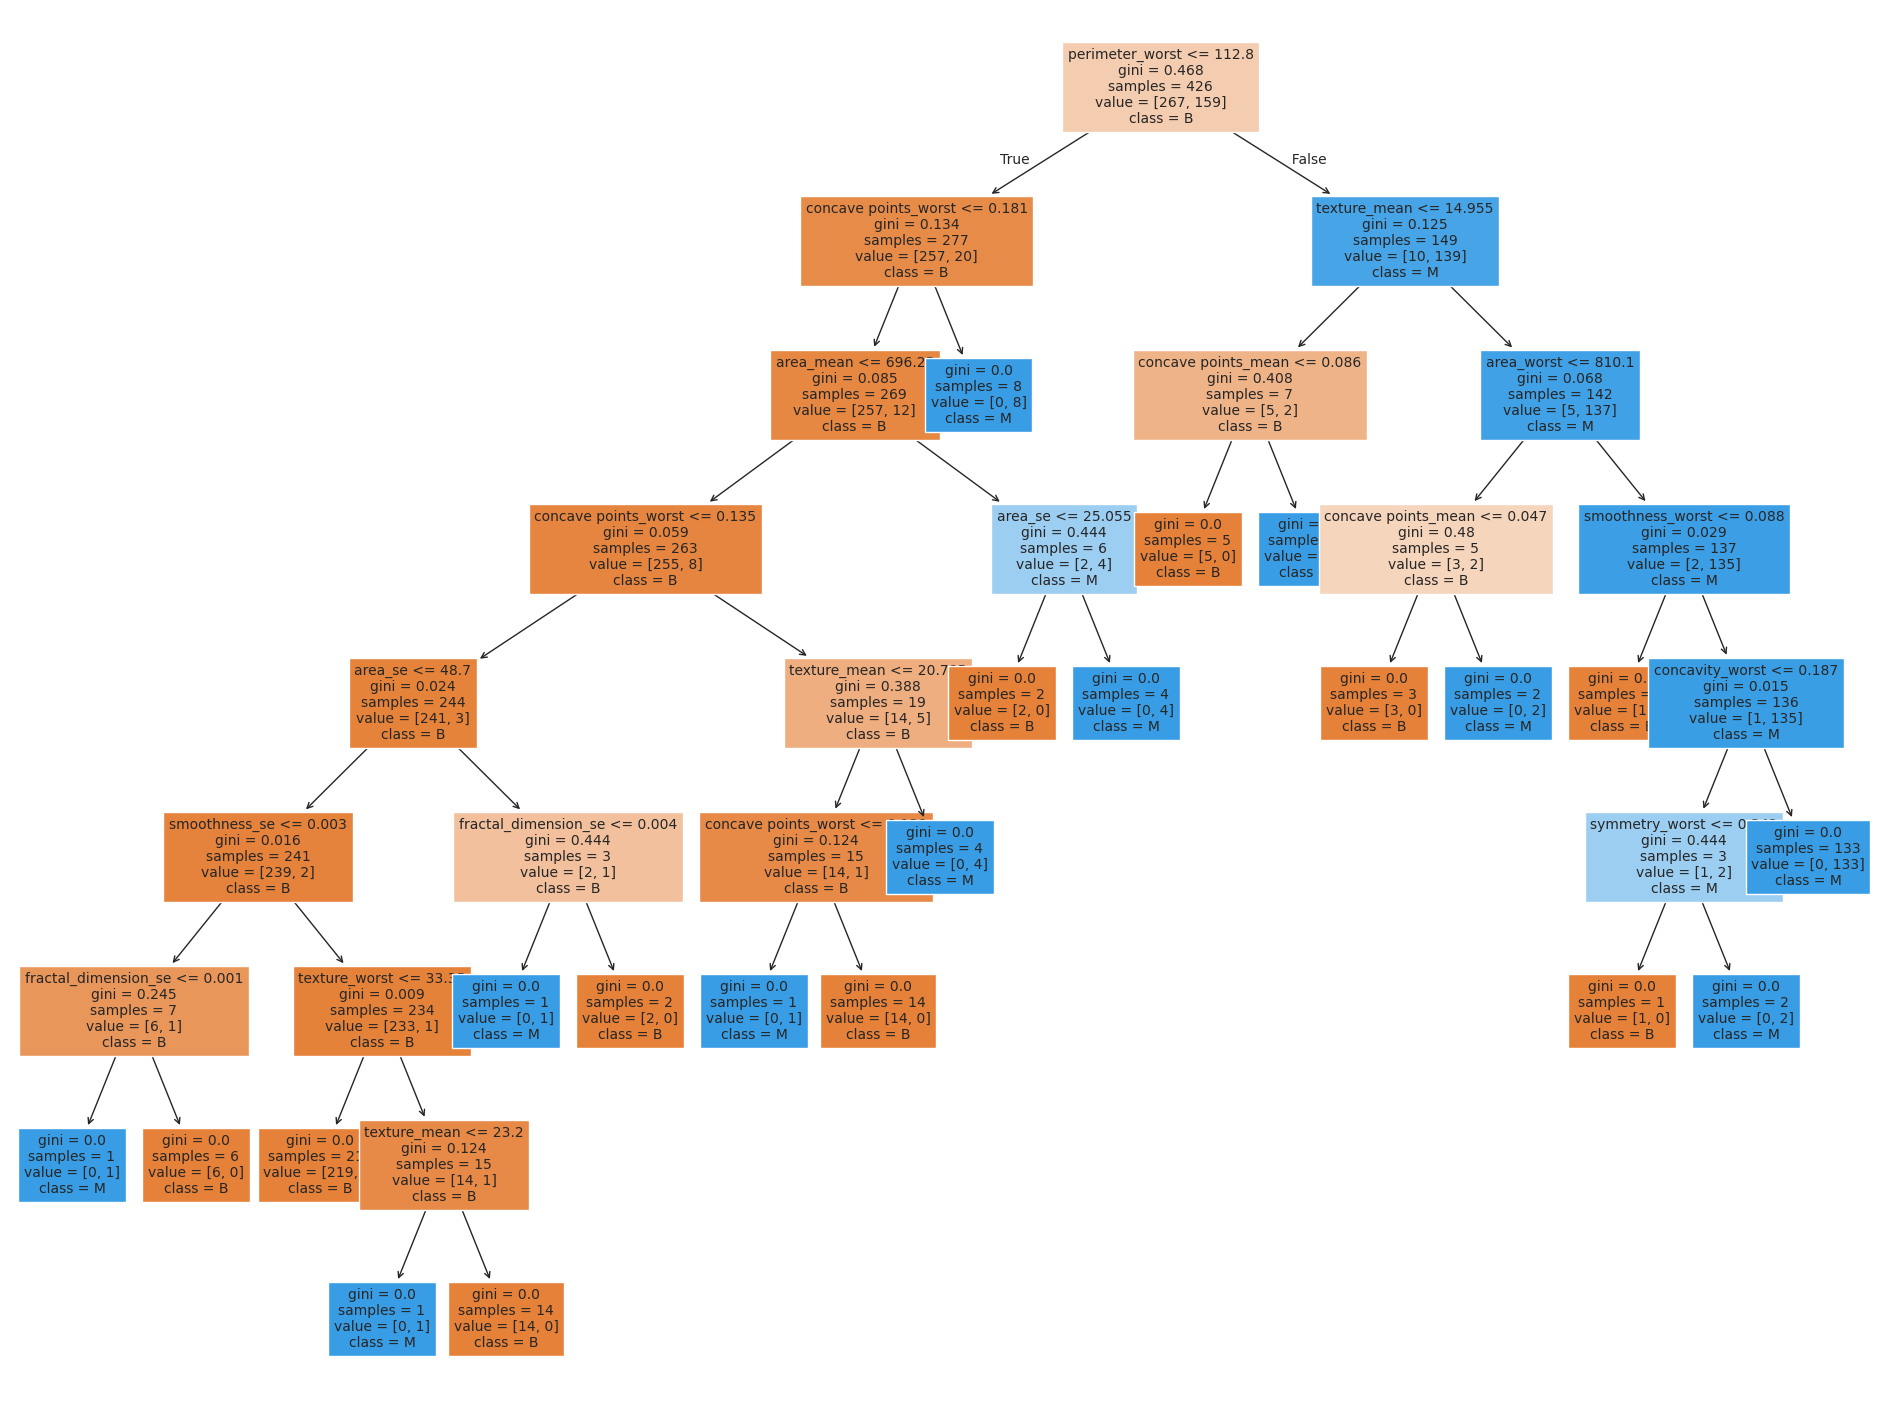

In [30]:
fig, ax = plt.subplots(figsize=(24, 18))

plot_tree(clf,
        ax=ax,
        feature_names=X.columns,
        class_names=le.classes_,
        filled=True,
        fontsize=10
    )

plt.show()

In [33]:
clf.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [34]:
clf.get_depth()

8

In [35]:
clf.get_n_leaves()

21

Uma das funcionalidades importantes das árvores é a capacidade de avaliar a **importância das características** (atributos) utilizadas no modelo. Essa avaliação é acessível através do atributo `feature_importances_`.

O atributo `feature_importances_` de um `DecisionTreeClassifier` é um vetor numérico que indica a importância relativa de cada característica utilizada no modelo. Em outras palavras, ele quantifica o **quanto cada característica contribuiu para a redução da impureza** ao longo da árvore. Essas importâncias ajudam a entender quais características são mais relevantes para o modelo ao tomar decisões de classificação.

- **Interpretação do Modelo:** Compreender quais características influenciam mais o modelo pode fornecer insights sobre o problema em questão.
- **Seleção de Características:** Pode ajudar a identificar características menos relevantes, permitindo simplificar o modelo ou melhorar o desempenho ao remover ruídos.
- **Comunicação de Resultados:** Facilita a explicação do modelo para stakeholders não técnicos, destacando os fatores-chave que afetam as previsões.

A importância de uma característica é calculada com base em **quanto essa característica reduz a impureza dos nós** em que é utilizada para dividir os dados. A impureza é medida usando critérios como o **Índice Gini** ou a **Entropia**.

1. **Impureza Inicial:**
   - Antes de qualquer divisão, o nó raiz tem uma certa impureza, pois contém uma mistura de classes.

2. **Redução de Impureza em Cada Divisão:**
   - Cada vez que o nó é dividido usando uma característica, ocorre uma redução na impureza.
   - A redução de impureza é calculada como:
     $$
     \text{Redução de Impureza} = \text{Impureza do Nó Pai} - (\text{Peso do Filho Esquerdo} \times \text{Impureza do Filho Esquerdo} + \text{Peso do Filho Direito} \times \text{Impureza do Filho Direito})
     $$
     Onde o peso é a proporção de amostras que vão para cada nó filho.

3. **Acumulando a Importância:**
   - Para cada característica, soma-se a redução de impureza em todos os nós em que ela é usada para dividir os dados.
   - Isso resulta em um valor total de importância para cada característica.

4. **Normalização:**
   - Os valores de importância são normalizados para que a soma total seja 1.
   - Isso facilita a comparação relativa entre as características.

Para a característica $ j $, a importância $ I_j $ é calculada como:

$$
I_j = \sum_{t \in \text{Nós\_onde\_j\_é\_usada}} \frac{N_t}{N} \times (\text{Impureza}_t - \text{Impureza}_{t_{\text{esq}}} - \text{Impureza}_{t_{\text{dir}}})
$$

Onde:

- $ N $ é o número total de amostras.
- $ N_t $ é o número de amostras no nó $ t $.
- $ \text{Impureza}_t $ é a impureza do nó $ t $.
- $ \text{Impureza}_{t_{\text{esq}}} $ e $ \text{Impureza}_{t_{\text{dir}}} $ são as impurezas dos nós filhos esquerdo e direito, respectivamente.


## Exemplo Ilustrativo

Considere uma árvore de decisão simples com três características: `X1`, `X2` e `X3`.

- **Divisão no Nó Raiz:**
  - Característica usada: `X2`
  - Redução de impureza: 0.4

- **Divisão no Nó Filho Esquerdo:**
  - Característica usada: `X1`
  - Redução de impureza: 0.3

- **Divisão no Nó Filho Direito:**
  - Característica usada: `X2`
  - Redução de impureza: 0.2

- **Divisão no Nó Neto:**
  - Característica usada: `X3`
  - Redução de impureza: 0.1

**Cálculo das Importâncias:**

- `X1`:
  - Total de redução: 0.3
- `X2`:
  - Total de redução: 0.4 + 0.2 = 0.6
- `X3`:
  - Total de redução: 0.1

**Normalização:**

- Soma total: 0.3 + 0.6 + 0.1 = 1.0

Portanto, as importâncias normalizadas são:

- `X1`: 0.3 / 1.0 = 0.30
- `X2`: 0.6 / 1.0 = 0.60
- `X3`: 0.1 / 1.0 = 0.10


### Limitações do `feature_importances_`

Embora o `feature_importances_` seja uma ferramenta útil, ele possui algumas limitações que devem ser consideradas.

1. **Viés para Características com Mais Níveis ou Valores Únicos**

- **Problema:**
  - Características numéricas contínuas ou categóricas com muitos níveis tendem a ser selecionadas mais frequentemente nas divisões, não necessariamente porque são mais importantes, mas porque têm mais possibilidades de criar divisões.
- **Implicação:**
  - O modelo pode superestimar a importância dessas características em detrimento de outras igualmente ou mais relevantes.

2. **Ignora Interações entre Características**

- **Problema:**
  - O `feature_importances_` considera apenas a redução de impureza atribuível a cada característica individualmente.
- **Implicação:**
  - Não captura importâncias derivadas de interações entre características que podem ser importantes para o desempenho do modelo.

3. **Instabilidade em Árvores Profundas**

- **Problema:**
  - Pequenas alterações nos dados de treinamento podem levar a árvores diferentes, especialmente se a árvore não for podada.
- **Implicação:**
  - As importâncias calculadas podem variar significativamente com diferentes amostras de dados, reduzindo a confiabilidade da interpretação.

4. **Não Generaliza para Novos Dados**

- **Problema:**
  - As importâncias são calculadas com base nos dados de treinamento.
- **Implicação:**
  - Se o modelo estiver overfitting, as importâncias podem não refletir a relevância das características em novos dados.

5. **Interpretação Relativa**

- **Problema:**
  - As importâncias são relativas dentro do modelo treinado.
- **Implicação:**
  - Não é possível comparar diretamente as importâncias entre modelos diferentes ou conjuntos de dados diferentes.

6. **Não Diferencia entre Relações Lineares e Não Lineares**

- **Problema:**
  - A árvore de decisão pode capturar relações não lineares e interações complexas.
- **Implicação:**
  - O `feature_importances_` não indica o tipo de relação ou se a influência de uma característica é positiva ou negativa.
